In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV,train_test_split,cross_val_predict,cross_val_score
from sklearn.metrics import r2_score,mean_absolute_error,mean_absolute_percentage_error,mean_squared_error
from sklearn.linear_model import LinearRegression,Ridge,Lasso

# EDA

In [2]:
df=pd.read_excel('data/premiums_rest.xlsx')
df.head()

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,56,Male,Northeast,Married,3,Obesity,Occasional,Self-Employed,10L - 25L,14,Diabetes,Bronze,15610


In [3]:
df['genetical_risk']=0

In [4]:
df.shape

(29904, 14)

In [5]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants',
       'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount', 'genetical_risk'],
      dtype='object')

In [6]:
df.columns=df.columns.str.replace(' ','_').str.lower()
df.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount', 'genetical_risk'],
      dtype='object')

In [7]:
df.dtypes

age                       int64
gender                   object
region                   object
marital_status           object
number_of_dependants      int64
bmi_category             object
smoking_status           object
employment_status        object
income_level             object
income_lakhs              int64
medical_history          object
insurance_plan           object
annual_premium_amount     int64
genetical_risk            int64
dtype: object

# Data transformation

## Handel Null Values

In [8]:
df.isnull().sum()

age                      0
gender                   0
region                   0
marital_status           0
number_of_dependants     0
bmi_category             0
smoking_status           9
employment_status        1
income_level             9
income_lakhs             0
medical_history          0
insurance_plan           0
annual_premium_amount    0
genetical_risk           0
dtype: int64

In [9]:
df.dropna(inplace=True)# droping every null value

In [10]:
df.duplicated().sum()# finding duplicate values
# df.drop_duplicates(inplace=True) if u want to delete the duplicate values

np.int64(0)

In [11]:
round(df.describe(),2)

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,29886.00,29886.00,29886.00,29886.00,29886.0
mean,43.40,2.38,23.36,20892.30,0.0
std,13.41,1.43,24.74,6936.81,0.0
min,26.00,-3.00,1.00,3625.00,0.0
25%,34.00,1.00,7.00,15697.25,0.0
50%,42.00,3.00,17.00,20489.00,0.0
75%,52.00,3.00,32.00,26360.00,0.0
max,356.00,5.00,930.00,43471.00,0.0


In [12]:
df[df.number_of_dependants<0].shape

(50, 14)

## number_of_dependants column tranformation

In [13]:
df[df.number_of_dependants<0]['number_of_dependants'].unique() # ask your data engineer about those negative values, he said they are positive values but while collecting data some mistake happened,so convert those negative values to positive

array([-1, -3])

In [14]:
df['number_of_dependants']=abs(df['number_of_dependants'])# converting negative values to positive
df[df.number_of_dependants<0]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk


In [15]:
df.number_of_dependants.describe()

count    29886.000000
mean         2.385933
std          1.421137
min          0.000000
25%          1.000000
50%          3.000000
75%          3.000000
max          5.000000
Name: number_of_dependants, dtype: float64

In [16]:
df.select_dtypes(['float64','int64'])# getting numarical values

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
0,26,0,6,9053,0
1,29,2,6,16339,0
2,49,2,20,18164,0
3,30,3,77,20303,0
4,56,3,14,15610,0
...,...,...,...,...,...
29899,60,3,26,26370,0
29900,40,0,16,29496,0
29901,37,0,4,10957,0
29902,47,2,82,27076,0


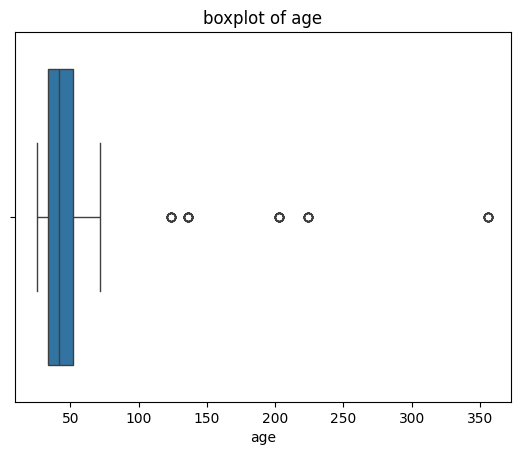

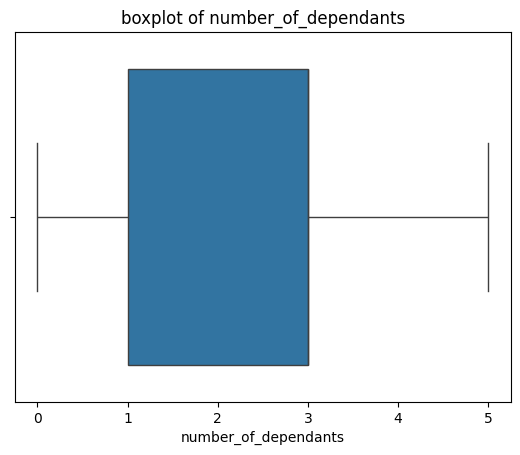

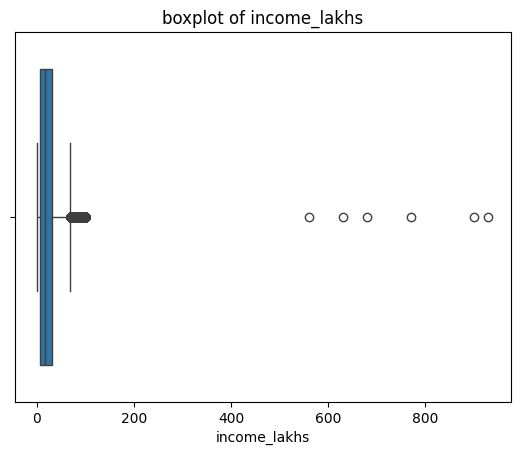

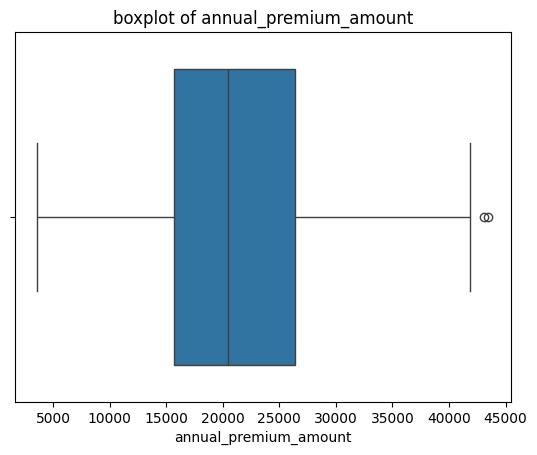

In [17]:
box =['age', 'number_of_dependants', 'income_lakhs',
       'annual_premium_amount']
for col in box:
    sns.boxplot(x=df[col])
    plt.title(f'boxplot of {col}')
    plt.show()

## removing outliers in age column

In [18]:
df[df['age']>100]['age'].unique()

array([224, 124, 136, 203, 356])

In [19]:
df1=df[df['age']<=100].copy()
df1.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,29828.000000,29828.000000,29828.000000,29828.000000,29828.0
mean,43.095380,2.387790,23.371530,20901.900563,0.0
std,11.041991,1.420641,24.751262,6928.457636,0.0
min,26.000000,0.000000,1.000000,6538.000000,0.0
25%,34.000000,1.000000,7.000000,15706.000000,0.0
50%,42.000000,3.000000,17.000000,20496.000000,0.0
75%,52.000000,3.000000,32.000000,26361.000000,0.0
max,72.000000,5.000000,930.000000,43471.000000,0.0


## using IQR to remove outliers in income_lakhs

<Axes: xlabel='income_lakhs', ylabel='Count'>

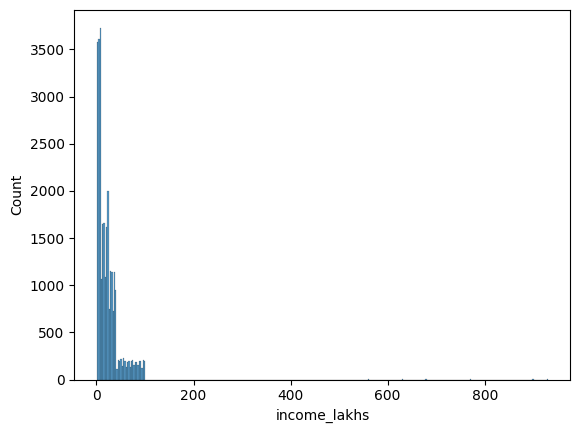

In [20]:
sns.histplot(df1['income_lakhs'])

In [21]:
def get_iqr(col):
    q1,q3=col.quantile([.25,.75])
    iqr=q3-q1
    lower_bound=q1-1.5*iqr
    upper_bound=q3+1.5*iqr
    return lower_bound,upper_bound

In [22]:
get_iqr(df1['income_lakhs'])

(-30.5, 69.5)

In [23]:
quantile_thresold=df1['income_lakhs'].quantile(0.999)
quantile_thresold

np.float64(100.0)

In [24]:
df1[df1['income_lakhs']>quantile_thresold]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk
1598,51,Male,Northwest,Married,4,Obesity,No Smoking,Self-Employed,> 40L,560,High blood pressure,Gold,30692,0
4657,35,Female,Northeast,Unmarried,0,Overweight,No Smoking,Salaried,> 40L,630,Diabetes,Gold,24010,0
5399,43,Male,Southeast,Married,3,Obesity,Regular,Salaried,> 40L,900,Diabetes & Thyroid,Gold,30848,0
6149,37,Female,Southeast,Married,3,Normal,No Smoking,Freelancer,> 40L,930,Diabetes,Silver,15945,0
21176,59,Male,Northwest,Married,2,Obesity,Occasional,Self-Employed,> 40L,770,Thyroid,Gold,31115,0
24489,48,Male,Northeast,Married,4,Obesity,No Smoking,Salaried,> 40L,680,No Disease,Gold,28926,0


In [25]:
df1[df1['income_lakhs']>quantile_thresold].shape

(6, 14)

In [26]:
df2=df1[df1.income_lakhs<=quantile_thresold].copy()
df2.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,29822.000000,29822.000000,29822.000000,29822.000000,29822.0
mean,43.094896,2.387734,23.226343,20900.689223,0.0
std,11.042430,1.420644,22.455408,6928.192115,0.0
min,26.000000,0.000000,1.000000,6538.000000,0.0
25%,34.000000,1.000000,7.000000,15705.250000,0.0
50%,42.000000,3.000000,17.000000,20495.500000,0.0
75%,52.000000,3.000000,32.000000,26360.000000,0.0
max,72.000000,5.000000,100.000000,43471.000000,0.0


In [27]:
box

['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount']

## Understanding dataset with the help of graphs

### Observe the plots, you can see the relations (correlation) of the columns

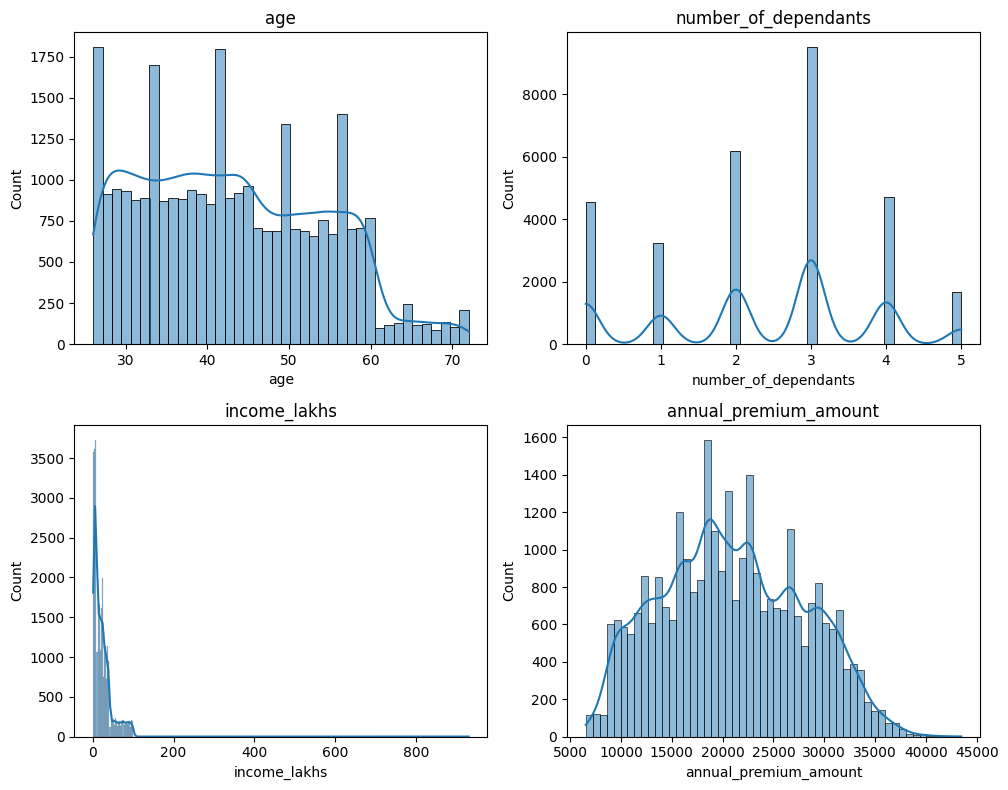

In [28]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,8))
for i,col in enumerate(box):
    ax=axs[i//2,i%2]
    sns.histplot(df1[col],kde=True,ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()
#plots with outliers

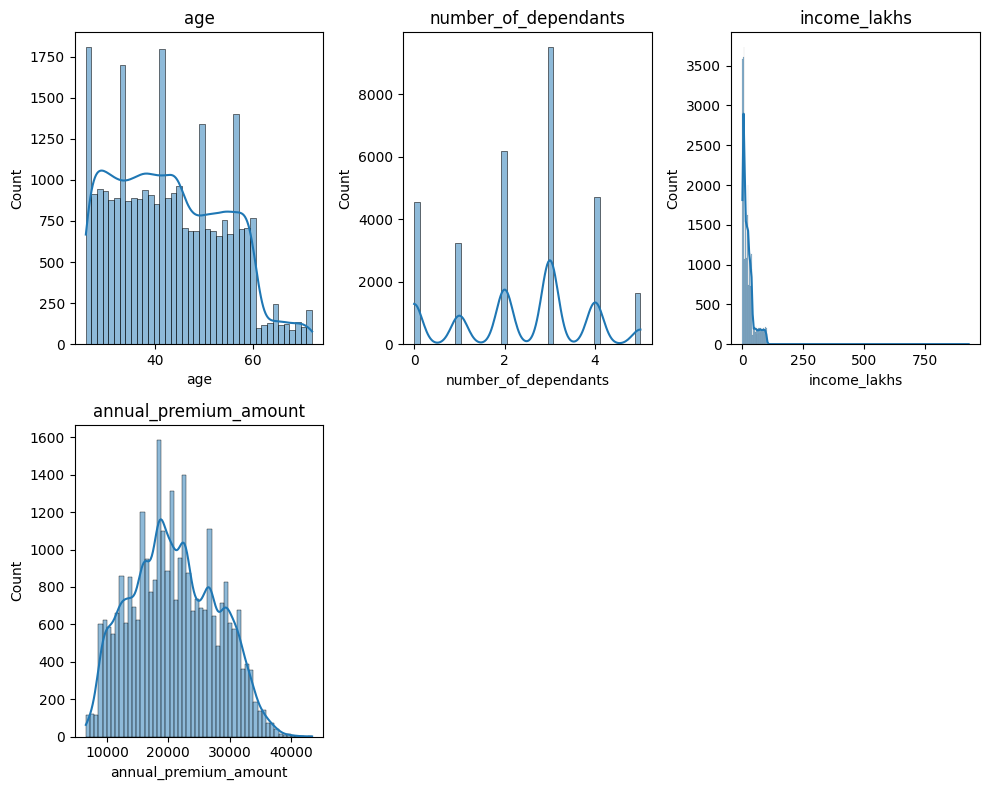

In [29]:
fig,axs=plt.subplots(nrows=2,ncols=3,figsize=(10,8))
for i,col in enumerate(box):
    ax=axs[i//3,i%3]
    sns.histplot(df1[col],kde=True,ax=ax)
    ax.set_title(col)
if len(box)%3!=0:
    for j in range(len(box),6):
        axs.flat[j].set_visible(False)
plt.tight_layout()
plt.show()
#plots with outliers

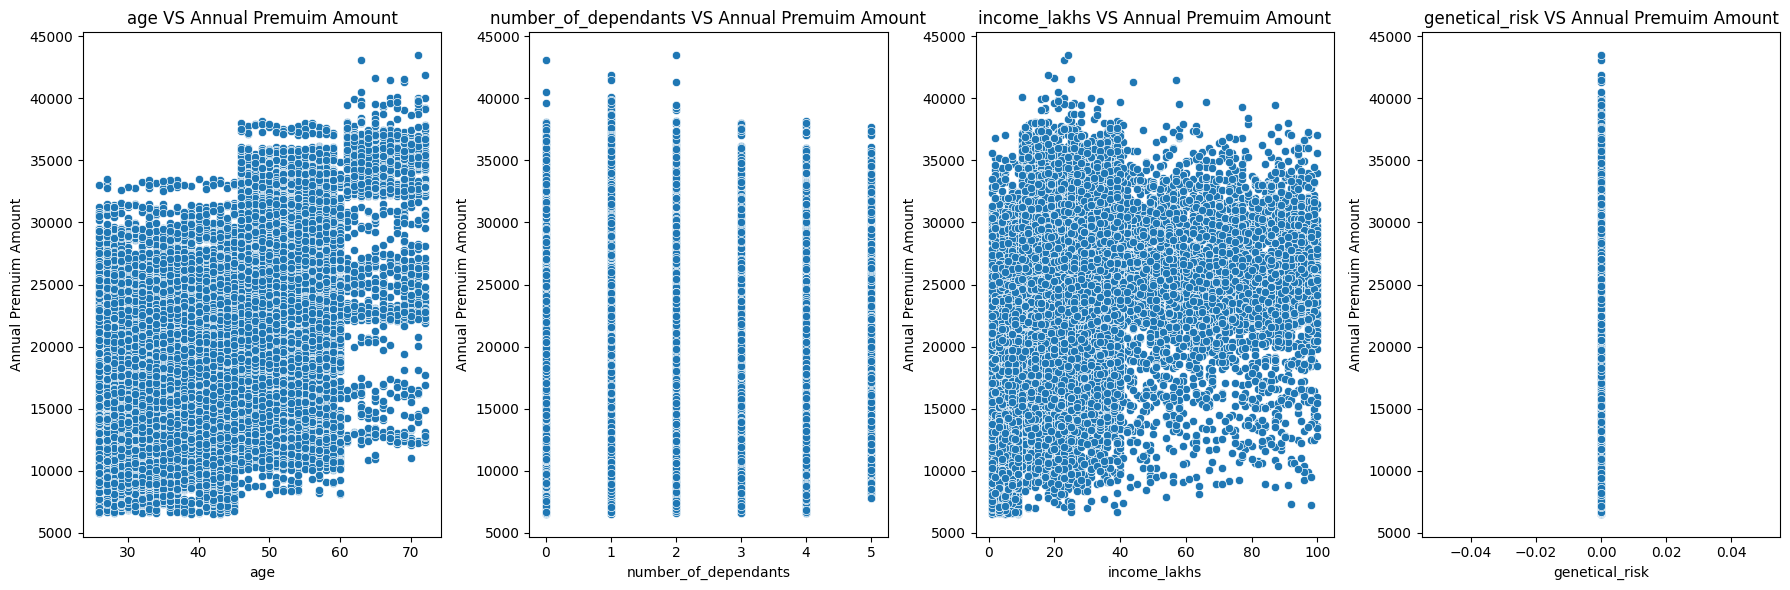

In [30]:
num=['age', 'number_of_dependants', 'income_lakhs','genetical_risk']#independent numeric columns
fig,axes=plt.subplots(1,len(num),figsize=(18,6))
for ax,col in zip(axes,num):
    sns.scatterplot(x=df2[col],y=df2['annual_premium_amount'],ax=ax)
    ax.set_title(f'{col} VS Annual Premuim Amount')
    ax.set_xlabel(col)
    ax.set_ylabel('Annual Premuim Amount')
plt.tight_layout()
plt.show()

In [31]:
categorical=df2.select_dtypes('string')
categorical.columns

Index([], dtype='object')

In [32]:
categorical_col=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status', 'income_level', 'medical_history','insurance_plan']
for col in categorical_col:
    print(col, ":",df2[col].unique())
#here in smoking_status column we got some error values ('Smoking=0','Does Not Smoke','Not Smoking')all mean the same

gender : ['Male' 'Female']
region : ['Northwest' 'Southeast' 'Northeast' 'Southwest']
marital_status : ['Unmarried' 'Married']
bmi_category : ['Normal' 'Obesity' 'Overweight' 'Underweight']
smoking_status : ['No Smoking' 'Regular' 'Occasional' 'Does Not Smoke' 'Not Smoking'
 'Smoking=0']
employment_status : ['Salaried' 'Self-Employed' 'Freelancer']
income_level : ['<10L' '10L - 25L' '> 40L' '25L - 40L']
medical_history : ['Diabetes' 'High blood pressure' 'No Disease'
 'Diabetes & High blood pressure' 'Thyroid' 'Heart disease'
 'High blood pressure & Heart disease' 'Diabetes & Thyroid'
 'Diabetes & Heart disease']
insurance_plan : ['Bronze' 'Silver' 'Gold']


In [33]:
df2['smoking_status'].unique()

array(['No Smoking', 'Regular', 'Occasional', 'Does Not Smoke',
       'Not Smoking', 'Smoking=0'], dtype=object)

In [34]:
df2['smoking_status']=df2['smoking_status'].replace({
    'Smoking=0':'No Smoking',
    'Does Not Smoke':'No Smoking',
    'Not Smoking':'No Smoking'
},inplace=True)

C:\Users\Jeevan kumar\AppData\Local\Temp\ipykernel_28528\949633080.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2['smoking_status']=df2['smoking_status'].replace({


In [35]:
df2['smoking_status'].unique()

array([None], dtype=object)

In [36]:
df2['gender'].value_counts(normalize=True)

gender
Male      0.549125
Female    0.450875
Name: proportion, dtype: float64

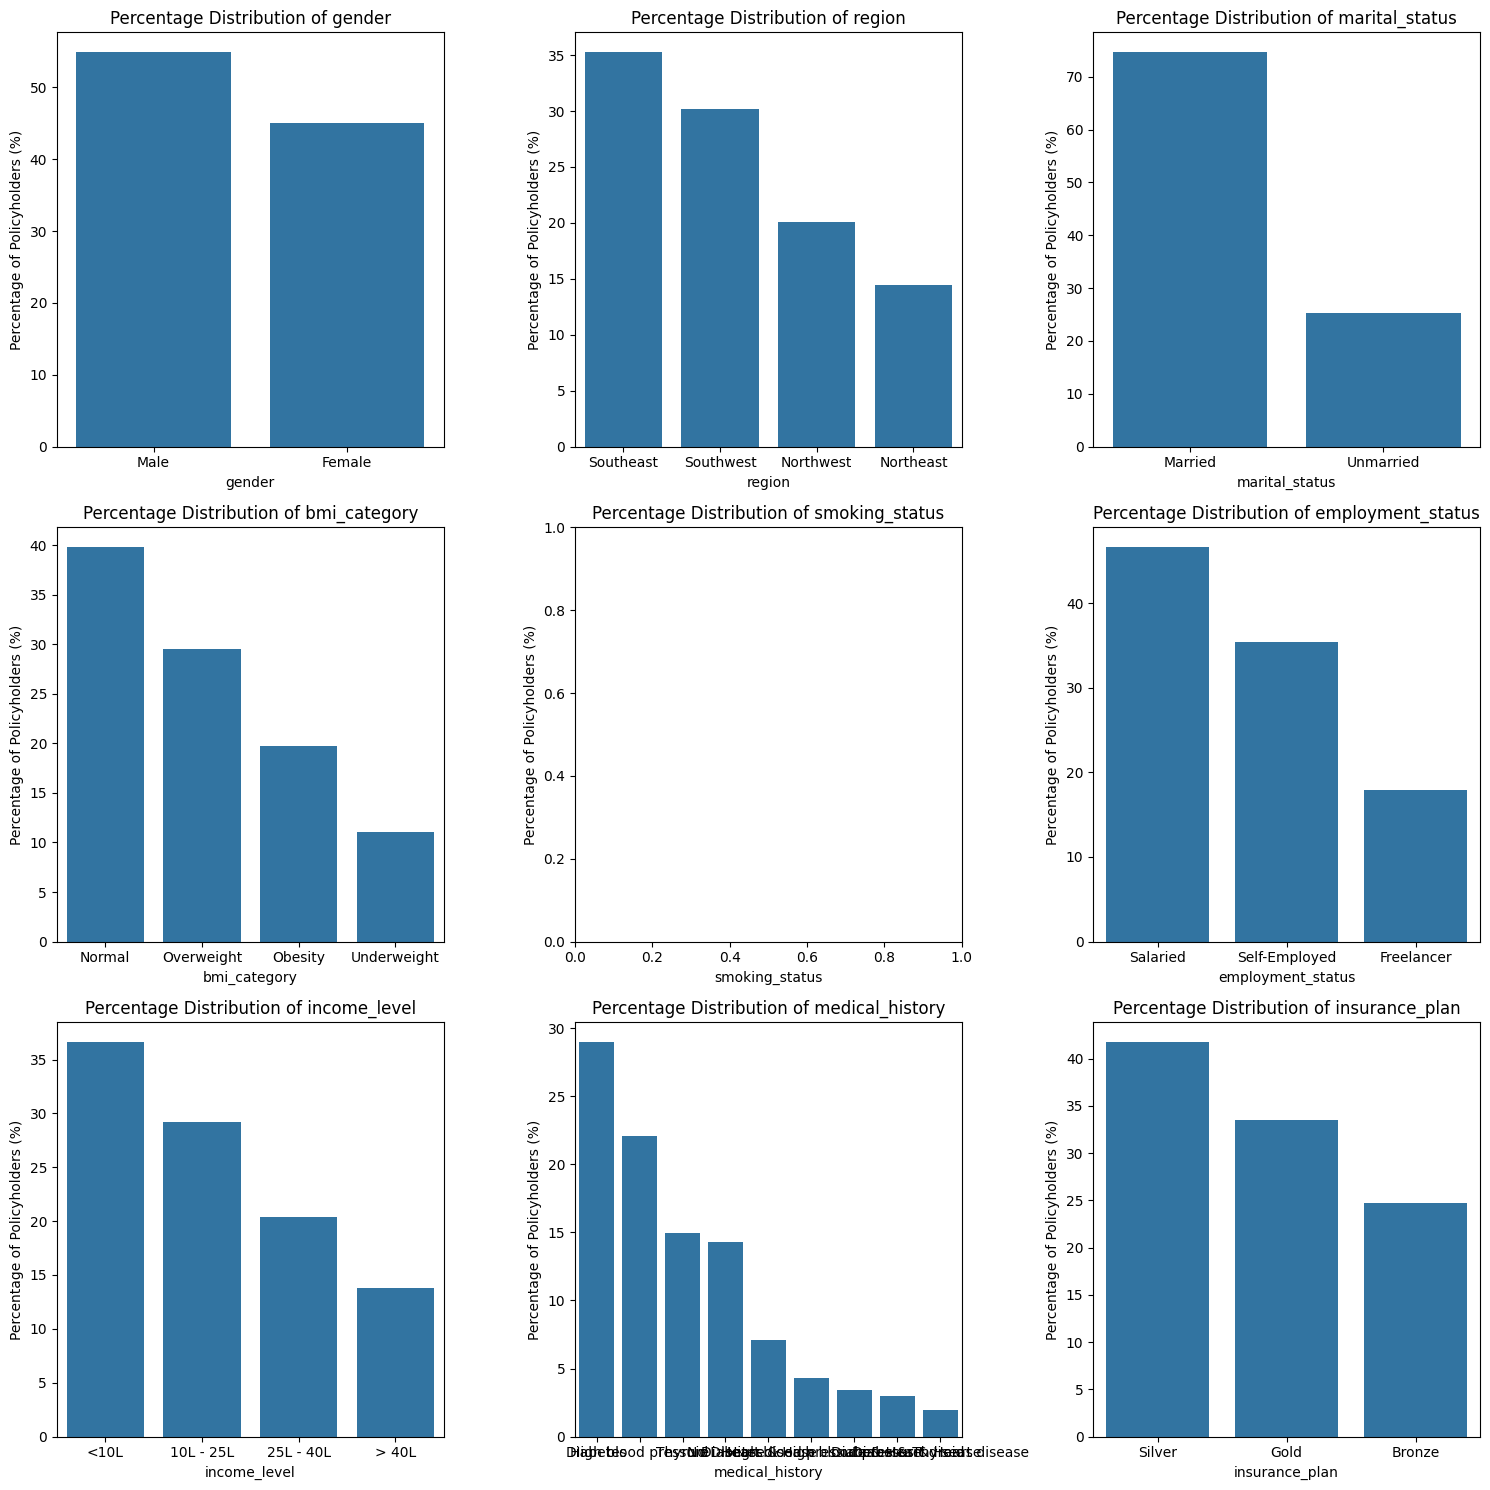

In [37]:
fig,axes=plt.subplots(3,3,figsize=(15,15))
axes=axes.flatten()
for ax,col in zip(axes,categorical_col):
    categorical_count=df2[col].value_counts(normalize=True)*100
    sns.barplot(x=categorical_count.index,y=categorical_count.values,ax=ax)
    ax.set_title(f'Percentage Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Percentage of Policyholders (%)')
plt.tight_layout()
plt.show()

<Axes: xlabel='income_level'>

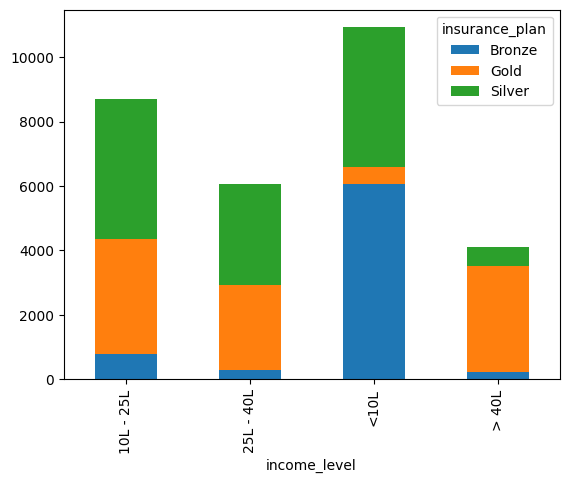

In [38]:
corsstab=pd.crosstab(df2['income_level'],df2['insurance_plan'])

corsstab.plot(kind='bar',stacked=True)

<Axes: xlabel='insurance_plan', ylabel='income_level'>

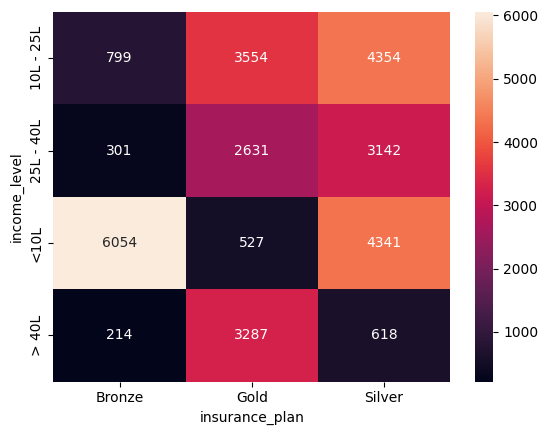

In [39]:
sns.heatmap(corsstab,annot=True,fmt='d')

# Feature Engineering

In [40]:
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk
0,26,Male,Northwest,Unmarried,0,Normal,None,Salaried,<10L,6,Diabetes,Bronze,9053,0
1,29,Female,Southeast,Married,2,Obesity,None,Salaried,<10L,6,Diabetes,Bronze,16339,0


In [41]:
df2.medical_history.unique()

array(['Diabetes', 'High blood pressure', 'No Disease',
       'Diabetes & High blood pressure', 'Thyroid', 'Heart disease',
       'High blood pressure & Heart disease', 'Diabetes & Thyroid',
       'Diabetes & Heart disease'], dtype=object)

In [42]:
df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

,0,1
0,diabetes,None
1,diabetes,None
2,high blood pressure,None
3,no disease,None
4,diabetes,None
...,...,...
29899,high blood pressure,None
29900,diabetes,thyroid
29901,no disease,None
29902,thyroid,None


In [43]:
df2[['disease1','disease2']]=df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

In [44]:
df2.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount', 'genetical_risk', 'disease1', 'disease2'],
      dtype='object')

In [45]:
risk_score={
    'diabetes':6,
    'heart disease':8,
    'high blood pressure':6,
    'thyroid':5,
    'no disease':0,
    'none':0
}

In [46]:
df2['disease1'] = df2['disease1'].fillna('none')
df2['disease2'] = df2['disease2'].fillna('none')
df2['total_risk_score'] = 0

In [47]:
for disease in ['disease1','disease2']:
    df2['total_risk_score']+=df2[disease].map(risk_score)

max_score=df2['total_risk_score'].max()
min_score=df2['total_risk_score'].min()
df2['normalized_risk_score']=(df2['total_risk_score']-min_score)/(max_score-min_score)
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,total_risk_score,normalized_risk_score
0,26,Male,Northwest,Unmarried,0,Normal,None,Salaried,<10L,6,Diabetes,Bronze,9053,0,diabetes,none,6.0,0.75
1,29,Female,Southeast,Married,2,Obesity,None,Salaried,<10L,6,Diabetes,Bronze,16339,0,diabetes,none,6.0,0.75


In [48]:
df2.sample(15)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,total_risk_score,normalized_risk_score
27314,39,Male,Northwest,Unmarried,0,Normal,None,Self-Employed,10L - 25L,24,High blood pressure,Silver,16173,0,high blood pressure,none,6.0,0.750
8249,54,Male,Northwest,Married,2,Obesity,None,Salaried,10L - 25L,11,Thyroid,Gold,33562,0,thyroid,none,5.0,0.625
23502,64,Male,Southeast,Married,1,Normal,None,Self-Employed,10L - 25L,25,Diabetes,Gold,32153,0,diabetes,none,6.0,0.750
18791,38,Male,Southwest,Married,3,Obesity,None,Self-Employed,> 40L,89,Heart disease,Gold,32995,0,heart disease,none,8.0,1.000
13501,50,Female,Northeast,Married,4,Overweight,None,Self-Employed,25L - 40L,30,High blood pressure,Gold,28980,0,high blood pressure,none,6.0,0.750
5488,33,Female,Southeast,Married,2,Obesity,None,Self-Employed,10L - 25L,11,Diabetes,Gold,26529,0,diabetes,none,6.0,0.750
17901,58,Female,Southwest,Married,3,Normal,None,Self-Employed,<10L,3,High blood pressure,Silver,21845,0,high blood pressure,none,6.0,0.750
11787,45,Female,Southeast,Unmarried,1,Normal,None,Self-Employed,25L - 40L,34,No Disease,Silver,16496,0,no disease,none,0.0,0.000
19431,26,Female,Southeast,Unmarried,2,Normal,None,Salaried,> 40L,77,No Disease,Gold,19822,0,no disease,none,0.0,0.000
29017,47,Female,Northeast,Married,5,Normal,None,Self-Employed,25L - 40L,27,High blood pressure,Silver,18857,0,high blood pressure,none,6.0,0.750


In [49]:
df2['disease2'].value_counts()

disease2
none                    26058
 heart disease           1595
 high blood pressure     1288
 thyroid                  881
Name: count, dtype: int64

In [50]:
df2['insurance_plan'].value_counts()

insurance_plan
Silver    12455
Gold       9999
Bronze     7368
Name: count, dtype: int64

In [51]:
df2['insurance_plan']=df2['insurance_plan'].map({'Bronze':1,'Silver':2,'Gold':3})#encoding insurance_plan column
df2.insurance_plan.unique()

array([1, 2, 3])

In [52]:
df2['income_level']=df2['income_level'].map({'<10L':1,'10L - 25L':2,'25L - 40L':3,'> 40L':4})#encoding income_level column
df2['income_level'].unique()

array([1, 2, 4, 3])

In [54]:
nominal_cols=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status']#'medical_history', 'disease1', 'disease2' columns are not use here
df3=pd.get_dummies(df2,columns=nominal_cols,drop_first=True,dtype=int)#converting catogarical columns to numarical columns by using get_dummies
df3.head()

,age,number_of_dependants,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,...,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,Diabetes,1,9053,0,diabetes,none,...,1,1,0,0,1,0,0,0,1,0
1,29,2,1,6,Diabetes,1,16339,0,diabetes,none,...,0,0,1,0,0,1,0,0,1,0
2,49,2,2,20,High blood pressure,2,18164,0,high blood pressure,none,...,0,0,0,0,0,0,0,0,0,1
3,30,3,4,77,No Disease,3,20303,0,no disease,none,...,0,0,1,0,0,0,0,0,1,0
4,56,3,2,14,Diabetes,1,15610,0,diabetes,none,...,1,0,0,0,0,1,0,0,0,1


In [55]:
df3.columns

Index(['age', 'number_of_dependants', 'income_level', 'income_lakhs',
       'medical_history', 'insurance_plan', 'annual_premium_amount',
       'genetical_risk', 'disease1', 'disease2', 'total_risk_score',
       'normalized_risk_score', 'gender_Male', 'region_Northwest',
       'region_Southeast', 'region_Southwest', 'marital_status_Unmarried',
       'bmi_category_Obesity', 'bmi_category_Overweight',
       'bmi_category_Underweight', 'employment_status_Salaried',
       'employment_status_Self-Employed'],
      dtype='object')

In [56]:
df4=df3.drop(['medical_history', 'disease1', 'disease2','total_risk_score'],axis=1)
df4.head()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,1,9053,0,0.75,1,1,0,0,1,0,0,0,1,0
1,29,2,1,6,1,16339,0,0.75,0,0,1,0,0,1,0,0,1,0
2,49,2,2,20,2,18164,0,0.75,0,0,0,0,0,0,0,0,0,1
3,30,3,4,77,3,20303,0,0.00,0,0,1,0,0,0,0,0,1,0
4,56,3,2,14,1,15610,0,0.75,1,0,0,0,0,1,0,0,0,1


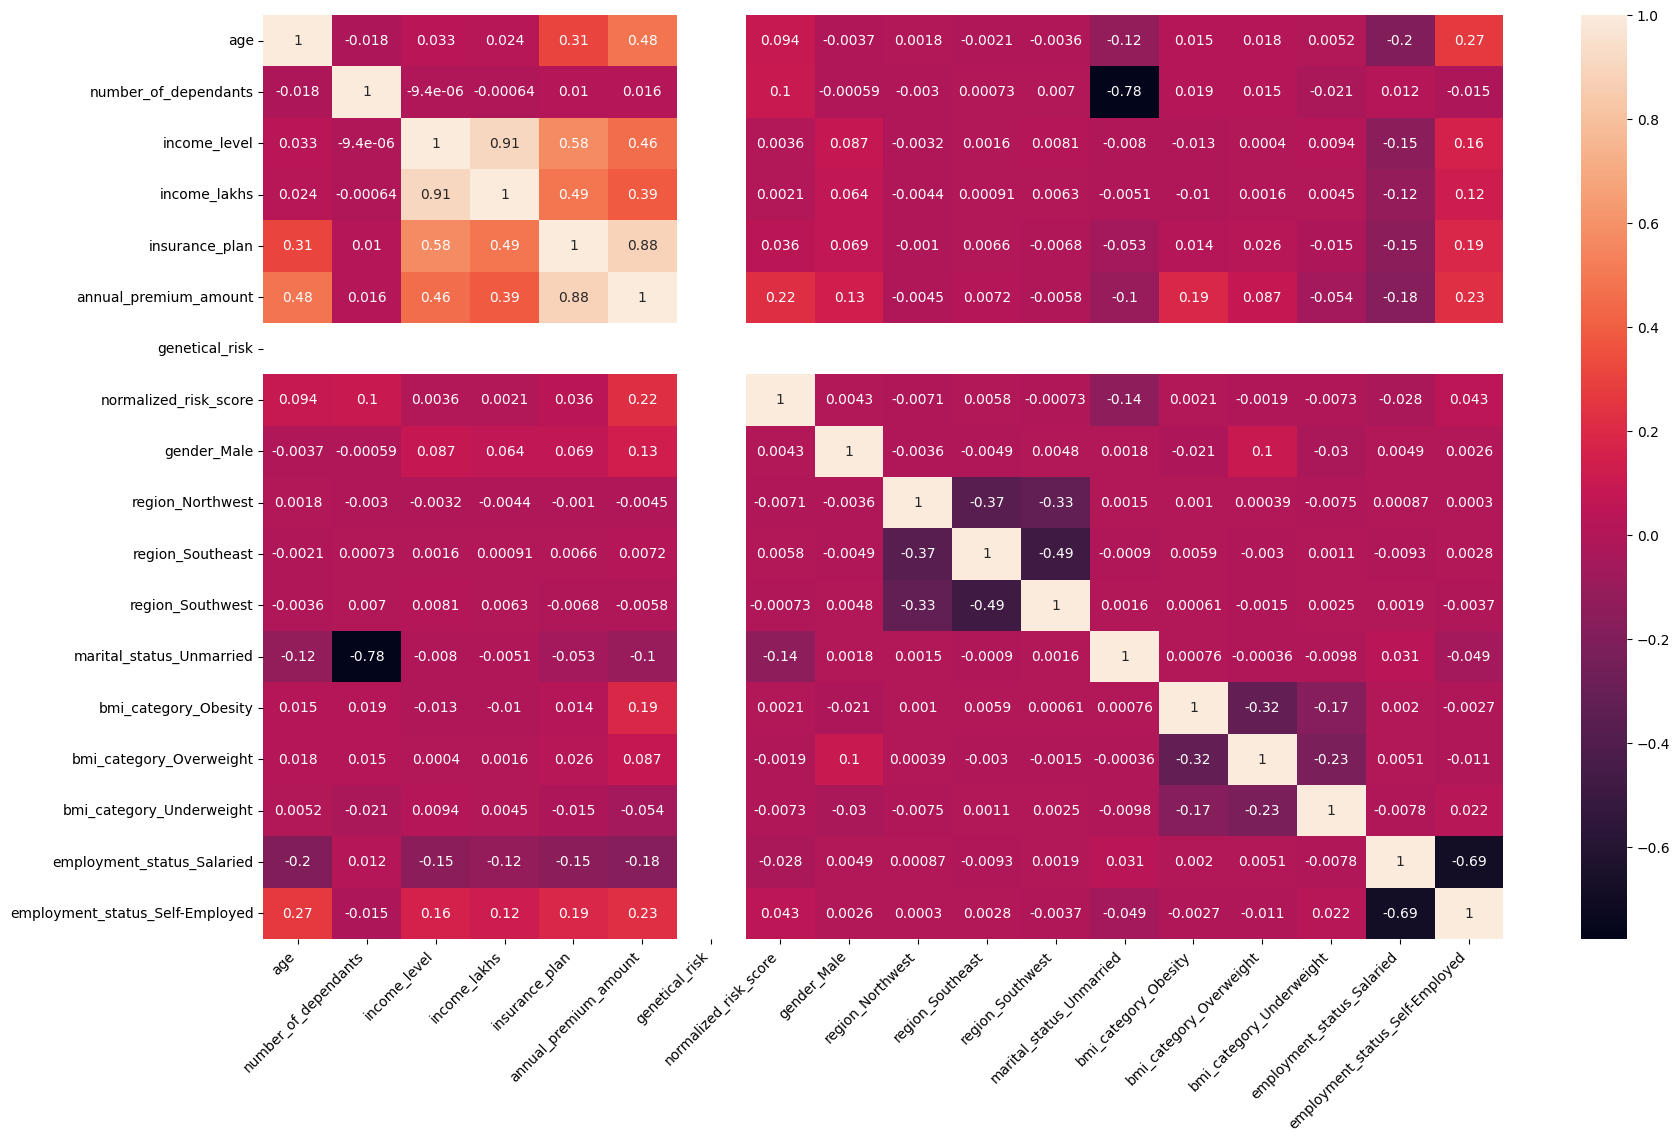

In [57]:
cn=df4.corr()

plt.figure(figsize=(20,12))
sns.heatmap(cn,annot=True)
plt.xticks(rotation=45,ha='right')
plt.yticks(rotation=0)
plt.tight_layout
plt.show()

In [58]:
#variation inflation factor

In [59]:
df4.head(2)

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,1,9053,0,0.75,1,1,0,0,1,0,0,0,1,0
1,29,2,1,6,1,16339,0,0.75,0,0,1,0,0,1,0,0,1,0


In [60]:
x=df4.drop(columns='annual_premium_amount')
y=df4['annual_premium_amount']

from sklearn.preprocessing import MinMaxScaler
cols_to_scale=['age','number_of_dependants','income_level','income_lakhs','insurance_plan','genetical_risk']
scaler=MinMaxScaler()

x[cols_to_scale]=scaler.fit_transform(x[cols_to_scale])
x.describe()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
count,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.0,26058.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000
mean,0.371628,0.477547,0.371225,0.224509,0.544112,0.0,0.626185,0.549125,0.200691,0.352693,0.301992,0.253336,0.196835,0.295051,0.110087,0.466132,0.354269
std,0.240053,0.284129,0.351111,0.226822,0.379009,0.0,0.290662,0.497589,0.400524,0.477816,0.459129,0.434929,0.397613,0.456073,0.313003,0.498860,0.478299
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.173913,0.200000,0.000000,0.060606,0.500000,0.0,0.625000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.347826,0.600000,0.333333,0.161616,0.500000,0.0,0.750000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.565217,0.600000,0.666667,0.313131,1.000000,0.0,0.750000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [61]:
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    data = data.copy() # Keep a copy of the data
    data = data.select_dtypes(include=np.number)# Keep only numeric columns
    data = data.replace([np.inf, -np.inf], np.nan)# Replace infinite values with NaN
    data = data.dropna() # Remove rows containing missing values
    data = data.loc[:, data.nunique() > 1] # Remove constant columns
    if data.shape[1] == 0:# Check whether any columns remain
        raise ValueError("No valid numeric columns available for VIF.")
    data = data.astype(float)# Convert to float
    # Calculate VIF
    vif_df = pd.DataFrame({
        'Column': data.columns,
        'VIF': [
            variance_inflation_factor(data.values, i)
            for i in range(data.shape[1])]})

    return vif_df.sort_values(by='VIF', ascending=False).reset_index(drop=True)

In [62]:
calculate_vif(x.drop(columns=['normalized_risk_score']))

,Column,VIF
0,income_level,6.558391
1,income_lakhs,5.652826
2,marital_status_Unmarried,2.665792
3,number_of_dependants,2.628242
4,region_Southeast,2.227239
5,region_Southwest,2.157242
6,employment_status_Self-Employed,2.005820
7,employment_status_Salaried,1.930470
8,region_Northwest,1.909221
9,insurance_plan,1.731810


In [63]:
x_reduced=x.drop(columns=['normalized_risk_score','income_level'])
x_reduced.head(2)

,age,number_of_dependants,income_lakhs,insurance_plan,genetical_risk,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,0.000000,0.0,0.050505,0.0,0.0,1,1,0,0,1,0,0,0,1,0
1,0.065217,0.4,0.050505,0.0,0.0,0,0,1,0,0,1,0,0,1,0


# Model training

In [64]:
x_train,x_test,y_train,y_test=train_test_split(x_reduced,y,test_size=.30,random_state=10)
print('x_train: ',x_train.shape)
print('x_test: ',x_test.shape)
print('y_train: ',y_train.shape)
print('y_test: ',x_test.shape)

x_train:  (20875, 15)
x_test:  (8947, 15)
y_train:  (20875,)
y_test:  (8947, 15)


In [65]:
model_l=LinearRegression()
model_l.fit(x_train,y_train)
model_l.score(x_test,y_test)

0.8809649626944106

In [66]:
model_l.score(x_train,y_train)#if score of train data set is higher,test score is lower,then the model is over fitting

0.8821512463532224

In [67]:
model_l.coef_

array([ 6.17702510e+03, -1.17707188e+03, -6.87720036e+02,  1.48139666e+04,
        1.36424205e-12,  1.00564548e+03, -9.18671888e+01, -4.17303883e+01,
       -3.60141880e+01, -1.13233345e+03,  3.93114703e+03,  2.02287860e+03,
        6.01483607e+02, -6.19537751e+01,  1.99683538e+02])

In [68]:
model_l.intercept_

np.float64(9581.469088749613)

In [69]:
feature_imp=model_l.coef_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df


,Coefficients
number_of_dependants,-1.177072e+03
marital_status_Unmarried,-1.132333e+03
income_lakhs,-6.877200e+02
region_Northwest,-9.186719e+01
employment_status_Salaried,-6.195378e+01
region_Southeast,-4.173039e+01
region_Southwest,-3.601419e+01
genetical_risk,1.364242e-12
employment_status_Self-Employed,1.996835e+02
bmi_category_Underweight,6.014836e+02


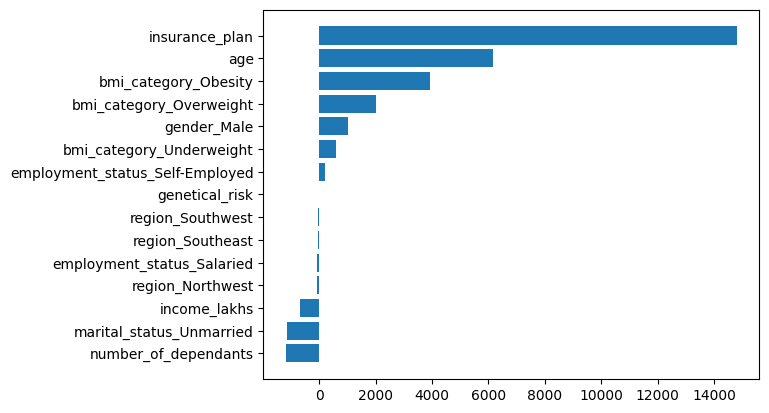

In [70]:
plt.barh(coef_df.index,coef_df['Coefficients'])
plt.show()

## Regularization

In [71]:
model_rg=Ridge(alpha=5)
model_rg.fit(x_train,y_train)
print('test score: ',model_rg.score(x_test,y_test))
print('train score: ',model_rg.score(x_train,y_train))

test score:  0.880971943128113
train score:  0.8821482417478399


## XGBoost model

In [72]:
from xgboost import XGBRegressor
model_xg=XGBRegressor()

model_xg.fit(x_train,y_train)
print('test score: ',model_xg.score(x_test,y_test))
print('train score: ',model_xg.score(x_train,y_train))

test score:  0.9007843732833862
train score:  0.932340145111084


In [73]:
# XGBoost is performing well so check its mean squared error
y_pred=model_xg.predict(x_test)

mse_lr=mean_squared_error(y_test,y_pred)
rmse_lr=np.sqrt(mse_lr)
print("XGBoost Regression ==>MSE: ",mse_lr,'RMSE: ',rmse_lr)

XGBoost Regression ==>MSE:  4694416.5 RMSE:  2166.660217939121


# Fine tuning

## Randoms search CV

In [74]:
model_xg=XGBRegressor()
param_grid={
    'n_estimators':[20,40,50],
    'learning_rate':[0.01,0.1,0.2],
    'max_depth':[3,4,5]
}

random_search=RandomizedSearchCV(model_xg,param_grid,n_iter=10,cv=3,scoring='r2',random_state=42)
random_search.fit(x_train,y_train)
random_search.best_score_

np.float64(0.9084310928980509)

In [75]:
best_model=random_search.best_estimator_

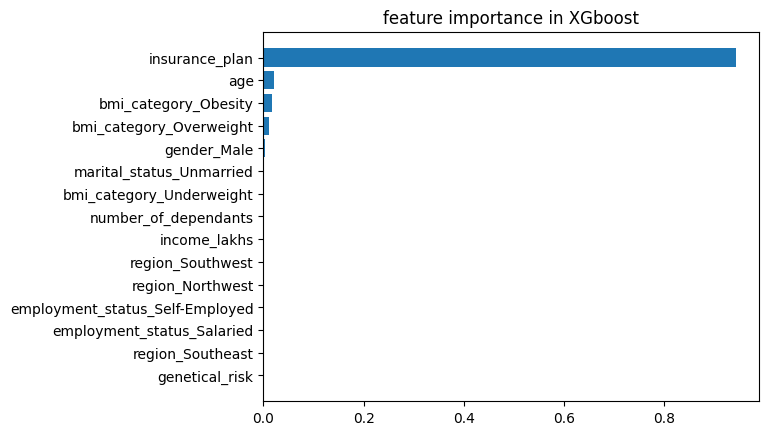

In [76]:
feature_imp=best_model.feature_importances_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df

plt.barh(coef_df.index,coef_df['Coefficients'])
plt.title('feature importance in XGboost')
plt.show()

# Error Analysis

In [77]:
y_pred=best_model.predict(x_test)

residuals=y_pred-y_test
residuals_pct=residuals*100/y_test

result_df=pd.DataFrame({
    'actual':y_test,
    'predicted':y_pred,
    'diff':residuals,
    'diff_pct':residuals_pct
})

result_df.head()

,actual,predicted,diff,diff_pct
19713,26895,27373.779297,478.779297,1.780180
14750,22734,17480.962891,-5253.037109,-23.106524
19932,21198,20543.044922,-654.955078,-3.089702
29643,9100,10650.320312,1550.320312,17.036487
17076,26434,27470.683594,1036.683594,3.921781


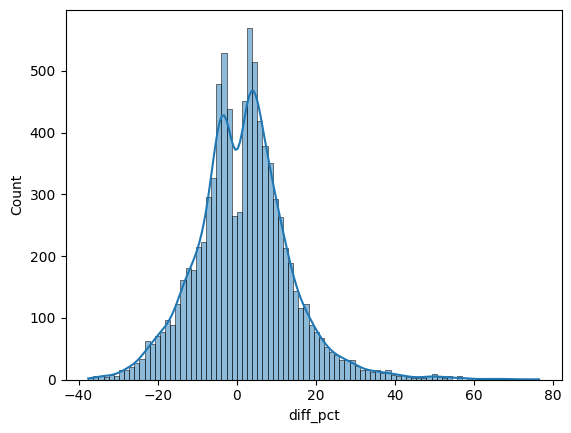

In [78]:
sns.histplot(result_df['diff_pct'],kde=True)
plt.show()

In [79]:
extreme_error_threshold=10
extreme_result_df=result_df[np.abs(result_df.diff_pct)>extreme_error_threshold]
extreme_result_df.shape

(3064, 4)

In [80]:
extreme_errors_pct=extreme_result_df.shape[0]*100/result_df.shape[0]
extreme_errors_pct

34.246116016541855

In [81]:
result_df[np.abs(result_df.diff_pct)>50].sort_values('diff_pct',ascending=False)

,actual,predicted,diff,diff_pct
12189,6571,11597.252930,5026.252930,76.491446
21910,6651,11584.102539,4933.102539,74.170840
25658,6804,11581.199219,4777.199219,70.211629
7547,6538,11007.380859,4469.380859,68.360062
14672,7044,11849.402344,4805.402344,68.219795
14286,6845,11364.716797,4519.716797,66.029464
10149,7084,11681.844727,4597.844727,64.904640
21455,6699,11007.380859,4308.380859,64.313791
11019,6715,10976.922852,4261.922852,63.468695
6517,6552,10631.066406,4079.066406,62.256813


# Export model for rest dataset

In [84]:
import os
from joblib import dump

os.makedirs('artifacts', exist_ok=True)
dump(best_model, 'app/artifacts/model_rest.joblib')
scaler_with_cols = {
    'scaler': scaler,
    'cols_to_scale': cols_to_scale
}
dump(scaler_with_cols, 'app/artifacts/scaler_rest.joblib')

['app/artifacts/scaler_rest.joblib']